# Fig. 3: Plots

Draws panels (a)–(c) and (d)–(e) of Fig. 3 from the data in `data/P_Ng/` and `data/Nc_Ng/`, produced by the notebooks in `notebooks/`. The two groups of panels are combined in Inkscape into `figures/fig3.svg` / `figures/fig3.pdf`.

The dotted line marks the breakdown of the adiabatic elimination of the excited levels: it is drawn where the more restrictive of the two conditions (`cond_adiab_r`, `cond_adiab_u`) reaches 1.

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.ticker import LogFormatterMathtext
from scipy.ndimage import zoom, gaussian_filter

In [2]:
class CustomLogFormatter(LogFormatterMathtext):
    def __call__(self, x, pos=None):
        if np.isclose(x, 1):
            return "1"
        elif np.isclose(x, 10):
            return "10"
        return super().__call__(x, pos)

In [3]:
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["cmr10"],
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,
    "axes.formatter.use_mathtext": True,
    "font.size": 14,
    "axes.labelsize": 14,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "axes.titlesize": 14,
})

r = 0.5 # Squeezing parameter
kappa = 0.07*2*np.pi*1e3/(2*np.pi) # Cavity decay (kHz)
w_cav = 2.3694723119046106e6*1e9 # Cavity frequency (rad/s)

## Panels (a)–(c): pump rate $w^{\rm p}$ vs. gain atoms $N_g$ ($N_c = 3000$)

Grids: 1000 × 1000 for the mean-field quantities (`numPD`), 150 × 150 for the cumulant expansion (`numCE`). Rates are converted to kHz.

In [4]:
numPD = 1000
numCE = 150

Nl_PD = np.logspace(1,np.log10(1e4),numPD)
Nl = np.logspace(1,np.log10(1e4),numCE)

d = "data/P_Ng/"

# Mean field
PD_P = np.load(d+"P_mf.npy")*1e6/(2*np.pi) # kHz
PD_comp = np.transpose(np.load(d+"mf_unstable_normal.npy"))
PD_cond_chaos = np.transpose(np.load(d+"mf_cond_chaos.npy"))
PD_cond_pump = np.transpose(np.load(d+"mf_cond_pump.npy"))
PD_wmin = np.load(d+"mf_wmin.npy")*1e6/(2*np.pi) # kHz
PD_wmax = np.load(d+"mf_wmax.npy")*1e6/(2*np.pi) # kHz

# Effective model, cut at N_g = 400
n_eff = np.transpose(np.load(d+"eff_n.npy"))[0]
gap_eff = np.transpose(np.load(d+"eff_linewidth.npy"))[0]*1e6/(2*np.pi) # kHz
corr_eff = np.transpose(np.load(d+"eff_SdagS.npy"))[0]
pob_las_eff = np.transpose(np.load(d+"eff_pop_gain.npy"))[0]

# Cumulant expansion
P = np.load(d+"P.npy")*1e6/(2*np.pi) # kHz
n = np.transpose(np.load(d+"n.npy"))
it = np.transpose(np.load(d+"iterations.npy"))
gap = np.transpose(np.load(d+"linewidth.npy"))*1e6/(2*np.pi) # kHz
corr = np.transpose(np.load(d+"SdagS.npy"))
pob_las = np.transpose(np.load(d+"pop_gain.npy"))
purc = np.transpose(np.load(d+"purcell.npy"))*1e6/(2*np.pi) # kHz
effSz = np.transpose(np.load(d+"cond_qubits.npy"))
cond_adiab = np.fmax(np.transpose(np.load(d+"cond_adiab_r.npy")), np.transpose(np.load(d+"cond_adiab_u.npy"))) # More restrictive condition

n[it > 10] = np.nan # Non-stationary points

hbar = 1.054571817e-34 # J·s
Pow = kappa*2*np.pi*1e3*w_cav*(n*np.cosh(2*r)+np.sinh(r)**2)*hbar # Output power (W)

X, Y = np.meshgrid(PD_P,Nl_PD)
x, y = np.meshgrid(P,Nl)

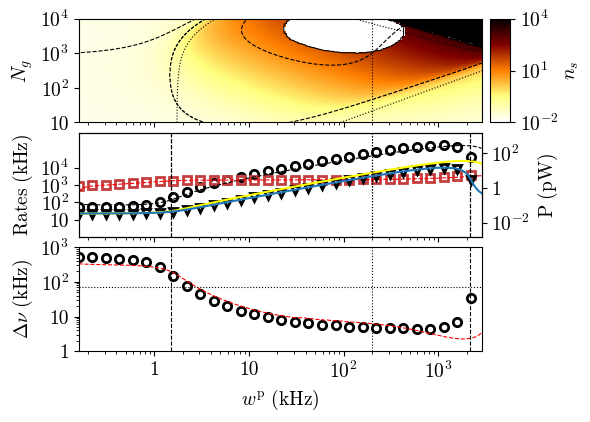

In [5]:
fig = plt.figure(figsize=(2.6*2,2.16*2))

# Axis layout

gs = fig.add_gridspec(3, 1, width_ratios=[1], height_ratios=[1,1,1], hspace=0.1, wspace=0.5)

ax_n = fig.add_subplot(gs[0,0])
cut_corr = fig.add_subplot(gs[1,0])
cut_gap = fig.add_subplot(gs[2,0])

yrange = [1e0,1e6]
yticks = [1e1,1e2,1e3,1e4]
xticks = [1,1e1,1e2,1e3]

# Photonic population

nrm = mpl.colors.LogNorm(vmin=0.01, vmax=1e4)
cbar = plt.colorbar(cm.ScalarMappable(norm=nrm, cmap=cm.afmhot_r), cax = ax_n.inset_axes([1.02, 0.00, 0.05, 1.00]), orientation="vertical", location='right')
cbar.set_label(r'$n_s$', labelpad=3) 
ax_n.pcolormesh(x, y, n, cmap=cm.afmhot_r, norm=nrm, rasterized=True)
ax_n.contour(x, y, it, levels=[10], colors='black', linestyles = "solid", linewidths = 0.8)
ax_n.contour(X, Y, PD_cond_chaos, levels=[0], colors='black', linestyles = "dashed", linewidths = 0.8)
# ax_n.contour(X, Y, PD_eff_nor, levels=[0], colors='black', linestyles = "dashed", linewidths = 0.8)
ax_n.contour(X, Y, PD_comp, levels=[0], colors='black', linestyles = "dashed", linewidths = 0.8)
ax_n.contour(X, Y, PD_cond_pump, levels=[0], colors='black', linestyles = "dotted", linewidths = 0.8)
ax_n.contour(x, y, effSz, levels=[.1], colors='black', linestyles = "dashed", linewidths = 0.8)
ax_n.contour(x, y, cond_adiab, levels=[1], colors='black', linestyles = "dotted", linewidths = 0.8)
ax_n.plot(PD_wmin, Nl_PD, color='black', linestyle = "dotted", linewidth = 0.8)
ax_n.plot(PD_wmax, Nl_PD, color='black', linestyle = "dotted", linewidth = 0.8)

ax_n.set_ylim([Nl.min(),Nl.max()])
ax_n.set_xlim([P.min(),P.max()])
ax_n.set_xscale('log')
ax_n.set_yscale('log')
ax_n.set_ylabel(r'$N_g$')
ax_n.set_xticks(xticks)
ax_n.set_yticks(yticks)
ax_n.tick_params(axis='x',labelbottom=False)
ax_n.xaxis.set_major_formatter(CustomLogFormatter())
ax_n.yaxis.set_major_formatter(CustomLogFormatter())

# Section gap

ind_Nl = np.argmin(np.abs(Nl-400))
ind_Nl_PD = np.argmin(np.abs(Nl_PD-400))
ind_nor_1 = np.argmax(PD_comp[ind_Nl_PD,0:(int(numPD/2)-1)])
ind_nor_2 = np.argmin(PD_comp[ind_Nl_PD,(int(numPD/2)-1):(numPD-1)])+int(numPD/2)-1
ind_P = np.argmin(np.abs(PD_cond_pump[ind_Nl_PD,:]))

cut_gap.plot(P, gap[ind_Nl,:], '.', fillstyle='none', markeredgewidth=2, color='black', markevery=5, markersize=12)
cut_gap.plot(P, gap_eff, color='red', linestyle = "dashed", linewidth = 0.8)
cut_gap.plot([PD_P[ind_nor_1],PD_P[ind_nor_1]], yrange, color='black', linestyle = "dashed", linewidth = 0.8)
cut_gap.plot([PD_P[ind_nor_2],PD_P[ind_nor_2]], yrange, color='black', linestyle = "dashed", linewidth = 0.8)
cut_gap.plot([PD_P[ind_P],PD_P[ind_P]], yrange, color='black', linestyle = "dotted", linewidth = 0.8)
cut_gap.plot(PD_P, kappa*np.ones(numPD), color='black', linestyle = "dotted", linewidth = 0.8)

cut_gap.set_ylabel(r'$\Delta\nu\ (\text{kHz})$')
cut_gap.set_xlabel(r'$w^\text{p}\ (\text{kHz})$')
cut_gap.set_ylim([1e0,1e3])
cut_gap.set_xlim([PD_P.min(),PD_P.max()])
cut_gap.set_xscale('log')
cut_gap.set_yscale('log')
cut_gap.set_xticks(xticks)
cut_gap.xaxis.set_major_formatter(CustomLogFormatter())
cut_gap.yaxis.set_major_formatter(CustomLogFormatter())

# cut_gap.set_yticks(yticks)

# Section correlations

cut_corr.plot(P, (corr)[ind_Nl,:]*purc[ind_Nl], '.', fillstyle='none', markeredgewidth=2, color='black', markevery=5, markersize=12, label=r'$\langle \hat S^\dagger \hat S\rangle$',)
cut_corr.plot(P, (pob_las*Nl[:, None])[ind_Nl,:]*purc[ind_Nl], 's', fillstyle='none', markeredgewidth=2, color='#c53e3e', markevery=5, markersize=6, label=r'$N_g\langle \hat \sigma^\dagger \hat \sigma\rangle$')
cut_corr.plot(P,(corr_eff)*purc[ind_Nl],color='black', linestyle = "dashed", linewidth = 0.8)
cut_corr.plot(P,(pob_las_eff*Nl[ind_Nl])*purc[ind_Nl],color='red', linestyle = "dashed", linewidth = 0.8)
cut_corr.plot([PD_P[ind_nor_1],PD_P[ind_nor_1]], yrange, color='black', linestyle = "dashed", linewidth = 0.8)
cut_corr.plot([PD_P[ind_nor_2],PD_P[ind_nor_2]], yrange, color='black', linestyle = "dashed", linewidth = 0.8)
cut_corr.plot([PD_P[ind_P],PD_P[ind_P]], yrange, color='black', linestyle = "dotted", linewidth = 0.8)

cut_corr.plot(P, (n[ind_Nl,:]*np.cosh(2*r)+np.sinh(r)**2)*kappa, 'v', fillstyle='none', markeredgewidth=2, color='black', markevery=5, markersize=6)
cut_corr.plot(P, (n_eff*np.cosh(2*r)+np.sinh(r)**2)*kappa, color='yellow')
cut_corr.plot([PD_P[ind_nor_1],PD_P[ind_nor_1]], yrange, color='black', linestyle = "dashed", linewidth = 0.8)
cut_corr.plot([PD_P[ind_nor_2],PD_P[ind_nor_2]], yrange, color='black', linestyle = "dashed", linewidth = 0.8)
cut_corr.plot([PD_P[ind_P],PD_P[ind_P]], yrange, color='black', linestyle = "dotted", linewidth = 0.8)

cut_corr.set_ylim(yrange)
cut_corr.set_xlim([PD_P.min(),PD_P.max()])
cut_corr.set_xscale('log')
cut_corr.set_yscale('log')
cut_corr.xaxis.set_major_formatter(CustomLogFormatter())
cut_corr.yaxis.set_major_formatter(CustomLogFormatter())
cut_corr.tick_params(axis='x',labelbottom=False)
cut_corr.set_xlabel(r'$w^\text{p}\ (\text{kHz})$')
cut_corr.set_ylabel(r'$\text{Rates}\ (\text{kHz})$')
cut_corr.set_yticks(yticks)
# cut_corr.legend()

cut_P = plt.twinx(cut_corr)
cut_P.plot(P, Pow[ind_Nl,:]*1e12)
cut_P.set_ylabel(r'$\text{P}\ (\text{pW})$')
cut_P.set_yscale('log')
cut_P.set_ylim([1.5*1e-3,1.5*1e3])
cut_P.xaxis.set_major_formatter(CustomLogFormatter())
cut_P.yaxis.set_major_formatter(CustomLogFormatter())
cut_P.set_yticks([1e-2,1,100])
cut_P.set_xticks(xticks)

plt.savefig("figures/panels_abc.svg", bbox_inches="tight")
plt.show()

## Panels (d)–(e): cooling atoms $N_c$ vs. gain atoms $N_g$ ($r = 0.5$)

In [6]:
numPD = 1000
numCE = 150

Nl_PD = np.logspace(1,np.log10(2e4),numPD)
Nc_PD = np.logspace(2,np.log10(2e4),numPD)
Nl = np.logspace(1,np.log10(2e4),numCE)
Nc = np.logspace(2,np.log10(2e4),numCE)

d = "data/Nc_Ng/"

# Mean field
PD_eff_las = np.transpose(np.load(d+"mf_unstable_lasing.npy"))
PD_comp = np.transpose(np.load(d+"mf_unstable_normal.npy"))

# Cumulant expansion
n = np.transpose(np.load(d+"n.npy"))
it = np.transpose(np.load(d+"iterations.npy"))
effSz = np.transpose(np.load(d+"cond_qubits.npy"))
cond_r = np.transpose(np.load(d+"cond_r.npy"))
cond_adiab = np.fmax(np.transpose(np.load(d+"cond_adiab_r.npy")), np.transpose(np.load(d+"cond_adiab_u.npy"))) # More restrictive condition
cond_cool = np.transpose(np.load(d+"cond_cool.npy"))
sq_seed = np.transpose(np.load(d+"dX2_seed.npy"))

Phases of panel (d): the boundaries computed on the cumulant grid are interpolated to the mean-field grid. Values: 0 squeezed vacuum (white), 1 squeezed lasing (blue), 2 non-adiabatic (red), 3 non-stationary (transparent, hatched in Inkscape), 4 imperfect squeezed lasing (yellow).

In [7]:
factor = numPD/numCE
PD_cond_r = zoom(cond_r, zoom=factor, order=3)
PD_effSz = zoom(effSz, zoom=factor, order=3)

PD = (PD_eff_las+PD_comp).astype(float)
X, Y = np.meshgrid(Nc_PD,Nl_PD)

for i in range(numPD):
    for j in range(numPD):
        if PD_effSz[i,j]>.1:
            PD[i,j] = 2
        elif PD_cond_r[i,j]<1 and PD[i,j]==1:
            PD[i,j] = 4

x, y = np.meshgrid(Nc,Nl)

Panel (e): colour encodes $\Delta\hat X$ of the seeded solution (hue, smoothed with a Gaussian filter that ignores NaNs) and the photon number $n_s$ (lightness).

In [8]:
db = 20*np.log10(np.sqrt(sq_seed)) # ΔX in dB: negative values mean squeezing

In [9]:
from scipy.ndimage import gaussian_filter

def nan_gaussian_blur(data, sigma, keep_nans=True):
    """
    Applies a Gaussian blur to a 2D array while ignoring NaN values.
    
    Parameters:
    -----------
    data : 2D numpy array
        The input matrix containing NaNs.
    sigma : float
        The standard deviation of the Gaussian kernel (blur strength).
    keep_nans : bool
        If True, restores the original NaN mask exactly as it was.
        If False, allows the blur to cleanly interpolate/fill into the NaN regions.
    """
    # 1. Create a copy and replace NaNs with 0
    v = data.copy()
    nan_mask = np.isnan(v)
    v[nan_mask] = 0
    
    # 2. Create a binary weight matrix (1 for real data, 0 for NaNs)
    w = np.ones_like(data)
    w[nan_mask] = 0
    
    # 3. Blur both the zero-filled data and the weights
    v_blurred = gaussian_filter(v, sigma=sigma)
    w_blurred = gaussian_filter(w, sigma=sigma)
    
    # 4. Divide blurred data by blurred weights to normalize
    # (We use np.errstate to ignore division-by-zero warnings deep inside large NaN zones)
    with np.errstate(divide='ignore', invalid='ignore'):
        result = v_blurred / w_blurred
    
    # 5. Handle NaNs in the output
    if keep_nans:
        # Keep the NaN boundary exactly where it was originally
        result[nan_mask] = np.nan
    else:
        # Only put NaNs back where there was absolutely no data to interpolate from
        result[w_blurred == 0] = np.nan
        
    return result

blurred_db = nan_gaussian_blur(db, 3)

In [10]:
from matplotlib.colors import LinearSegmentedColormap, ListedColormap

blue_map = LinearSegmentedColormap.from_list(
    "white_blue_purple",
    [
        (0.0, (1.0, 1.0, 1.0)),          # white
        (0.15, (0.9, 0.9, 1.0)),          # very light blue
        (0.3, (0.369, 0.541, 0.867)),    # blue
        (1.0, (0.45, 0.0, 0.6)),         # purple
    ]
)

red_map = LinearSegmentedColormap.from_list(
    "white_orange_red",
    [
        (0.0, (1.0, 1.0, 1.0)),         # white
        (0.15, (1.000, 0.980, 0.941)),   # light orange
        (0.3, (1.000, 0.647, 0.000)),   # orange
        (1.0, (0.773, 0.243, 0.243)),   # red
    ]
)

yellow_map = LinearSegmentedColormap.from_list(
    "white_yellow",
    [
        (0.0, (1.0, 1.0, 1.0)),         # white
        (0.3, (1.000, 1.000, 0.941)),  # light yellow
        (1.0, (0.980, 0.796, 0.447)),   # yellow
    ]
)

PD_map = ListedColormap(
    [
        (1.000, 1.000, 1.000),  # white
        (0.369, 0.541, 0.867),  # blue
        (0.773, 0.243, 0.243),  # red
        (0.800, 0.753, 0.753, 0.000),  # transparent
        (0.980, 0.796, 0.447),  # yellow 
    ]
)


db_norm = np.where(blurred_db >= 0,blurred_db/33,blurred_db/4) # -1 ↔ -4 dB (squeezing), 1 ↔ 33 dB (anti-squeezing)
n_norm = (np.log10(n)-(-2))/(4.5-(-2))
n_norm = np.clip(n_norm, 0, 1)
db_norm = np.clip(db_norm, -1.0, 1.0)
n_norm = np.clip(n_norm, 0.0, 1.0)
dist_y = np.abs(db_norm) / np.nanmax(np.abs(db_norm))

rgb_image = np.ones((*x.shape, 3))*np.nan

C_up = red_map(n_norm)[..., :3]
C_mid = yellow_map(n_norm)[..., :3]
C_down = blue_map(n_norm)[..., :3]

mask_pos = db_norm > 0
rgb_image[mask_pos] = ((1 - dist_y[mask_pos, None]) * C_mid[mask_pos] + dist_y[mask_pos, None] * C_up[mask_pos])

mask_neg = db_norm < 0
rgb_image[mask_neg] = ((1 - dist_y[mask_neg, None]) * C_mid[mask_neg] + dist_y[mask_neg, None] * C_down[mask_neg])

In [11]:
leg_n = np.linspace(0, 1, numCE)
leg_db = np.linspace(-1, 1, numCE)

Leg_n, Leg_db = np.meshgrid(leg_n, leg_db)
dist_y = np.abs(Leg_db) / np.nanmax(np.abs(Leg_db))

leg_rgb = np.ones((*Leg_n.shape, 3))  

C_up = red_map(Leg_n)[..., :3]
C_mid = yellow_map(Leg_n)[..., :3]
C_down = blue_map(Leg_n)[..., :3]

mask_pos = Leg_db > 0
leg_rgb[mask_pos] = ((1 - dist_y[mask_pos, None]) * C_mid[mask_pos] + dist_y[mask_pos, None] * C_up[mask_pos])

mask_neg = Leg_db < 0
leg_rgb[mask_neg] = ((1 - dist_y[mask_neg, None]) * C_mid[mask_neg] + dist_y[mask_neg, None] * C_down[mask_neg])

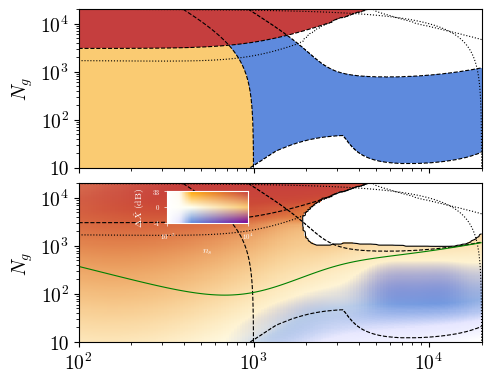

In [12]:
fig = plt.figure(figsize=(2.6*2,2.16*2))

# Axis layout

gs = fig.add_gridspec(2, 1, width_ratios=[1], height_ratios=[1,1], hspace=0.1, wspace=0.5)

ax_PD = fig.add_subplot(gs[0, 0])
ax_sq = fig.add_subplot(gs[1, 0])

# Phase_diagram

nrm = mpl.colors.Normalize(vmin=0, vmax=4)

ax_PD.pcolormesh(X, Y, PD, cmap=PD_map, norm=nrm, rasterized=True)
ax_PD.contour(X, Y, PD_eff_las, levels=[1], colors='black', linestyles = "dashed", linewidths = 0.8)
ax_PD.contour(X, Y, PD_comp, levels=[0], colors='black', linestyles = "dashed", linewidths = 0.8)
ax_PD.contour(x, y, effSz, levels=[.1], colors='black', linestyles = "dashed", linewidths = 0.8)
ax_PD.contour(x, y, cond_adiab, levels=[1], colors='black', linestyles = "dotted", linewidths = 0.8)
ax_PD.contour(x, y, cond_r, levels=[1], colors='black', linestyles = "dashed", linewidths = 0.8)
ax_PD.contour(X, Y, X+Y, levels=[2e4], colors='black', linestyles = "dotted", linewidths = 0.8)

ax_PD.set_ylabel(r'$N_g$')
ax_PD.set_xlabel(r'$N_c$')
ax_PD.set_ylim([Nl_PD.min(),Nl_PD.max()])
ax_PD.set_xlim([Nc_PD.min(),Nc_PD.max()])
ax_PD.set_xscale('log')
ax_PD.set_yscale('log')
ax_PD.tick_params(axis='x',labelbottom=False)
ax_PD.xaxis.set_major_formatter(CustomLogFormatter())
ax_PD.yaxis.set_major_formatter(CustomLogFormatter())

# Normalized squeezing after injection

# nrm = mpl.colors.Normalize(vmin=20*np.log10(np.sqrt(np.exp(-2*r))), vmax=-20*np.log10(np.sqrt(np.exp(-2*r))))
# cbar = plt.colorbar(cm.ScalarMappable(norm=nrm, cmap=cm.bwr), cax = ax_sq.inset_axes([1.02, 0.00, 0.05, 1.00]), orientation="vertical", location='right')
# cbar.set_label(r'$\Delta\hat X \;\text{(dB)}$', labelpad=3) 
ax_sq.pcolormesh(x, y, rgb_image, rasterized=True)
ax_sq.contour(x, y, it, levels=[10], colors='black', linestyles = "solid", linewidths = 0.8)
ax_sq.contour(X, Y, PD_eff_las, levels=[1], colors='black', linestyles = "dashed", linewidths = 0.8)
ax_sq.contour(X, Y, PD_comp, levels=[0], colors='black', linestyles = "dashed", linewidths = 0.8)
ax_sq.contour(x, y, effSz, levels=[.1], colors='black', linestyles = "dashed", linewidths = 0.8)
ax_sq.contour(x, y, cond_adiab, levels=[1], colors='black', linestyles = "dotted", linewidths = 0.8)
ax_sq.contour(x, y, cond_r, levels=[1], colors='black', linestyles = "dashed", linewidths = 0.8)
ax_sq.contour(x, y, x+y, levels=[2e4], colors='black', linestyles = "dotted", linewidths = 0.8)
ax_sq.contour(x, y, cond_cool, levels=[1], colors='green', linestyles = "solid", linewidths = 0.8)

ax_sq.set_ylabel(r'$N_g$')
ax_sq.set_ylim([Nl.min(),Nl.max()])
ax_sq.set_xlim([Nc.min(),Nc.max()])
ax_sq.set_xscale('log')
ax_sq.set_yscale('log')
ax_sq.xaxis.set_major_formatter(CustomLogFormatter())
ax_sq.yaxis.set_major_formatter(CustomLogFormatter())

ax_inset = ax_sq.inset_axes([0.22, 0.75, 0.2, 0.2])

ax_inset.pcolormesh(Leg_n, Leg_db, leg_rgb, rasterized=True)

ax_inset.set_ylabel(r"$\Delta\hat X\ (\text{dB})$", fontsize=7, color='white')
ax_inset.set_xlabel("$n_s$", fontsize=7, color='white')
ax_inset.set_xlim(0, 1)
ax_inset.set_ylim(-1, 1)
ax_inset.set_yticks([-1, 0, 1])
ax_inset.set_yticklabels(['-4', '0', '33'], fontsize=5, color='white')
ax_inset.set_xticks([0, 1])
ax_inset.set_xticklabels(['$10^{-2}$', '$10^4$'], fontsize=5, color='white')
for spine in ax_inset.spines.values():
    spine.set_color('white')
ax_inset.tick_params(colors='white', width=0.5, length=2)

plt.savefig("figures/panels_de.svg", bbox_inches="tight")
plt.show()